<!-- gs-watermark -->
> **© 2026 Gokaran Shukla** · part of [hopforge](https://github.com/Gokaran-Shukla/hopforge) · MIT License — any reuse must keep this copyright notice and credit the author.

# 22 · DMRG and matrix-product states: interacting chains with hundreds of sites

Exact diagonalisation (tutorial 19) stops at about 20–30 sites. `hf.dmrg` represents the ground state as a
**matrix-product state** (MPS) and optimises it site by site (White's density-matrix renormalisation group).
The cost grows only linearly with length for a fixed bond dimension $\chi$, so 1D chains with
**hundreds of sites** are routine. The truncation error tells you how converged the result is.

| Function | What it does |
|---|---|
| `build_mpo(L, sites, terms)` | any Hamiltonian $\sum c\,O_1O_2\cdots$ → compressed MPO (Jordan-Wigner strings automatic) |
| `heisenberg`, `tfim`, `aklt`, `hubbard`, `spinless_fermions` | ready-made MPOs |
| `from_model(model, L, U, V)` | any 1D hopforge `Model` + interactions |
| `dmrg(H, chi=[...], sweeps)` | two-site DMRG with a bond-dimension schedule |
| `excited_states(H, n)` | low-lying states by orthogonality penalties |
| `MPS.expect / correlation / entanglement` | measurements |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import hopforge as hf
M = hf.models
%matplotlib inline
D = hf.dmrg

## 1 · Any Hamiltonian as an MPO
Terms are lists of `(coefficient, [(operator, site), ...])`. Below: a $J_1$-$J_2$ chain in a field. The compressed MPO bond dimension is printed, and DMRG is checked against exact diagonalisation of the same MPO.

In [2]:
L = 10
terms = []
for i in range(L - 1):
    terms += [(0.5, [("Sp", i), ("Sm", i + 1)]), (0.5, [("Sm", i), ("Sp", i + 1)]), (1.0, [("Sz", i), ("Sz", i + 1)])]
for i in range(L - 2):
    terms += [(0.3 * 0.5, [("Sp", i), ("Sm", i + 2)]), (0.3 * 0.5, [("Sm", i), ("Sp", i + 2)]), (0.3, [("Sz", i), ("Sz", i + 2)])]
terms += [(-0.1, [("Sz", i)]) for i in range(L)]
H = D.build_mpo(L, D.SPIN, terms)
print("MPO bond dimensions:", H.bond_dims)
e_ed = np.linalg.eigvalsh(H.to_dense())[0]
r = D.dmrg(H, chi=[16, 32], sweeps=4)
print(f"ED  {e_ed:.12f}\nDMRG {r.energy:.12f}")

MPO bond dimensions: [4, 8, 8, 8, 8, 8, 8, 8, 4]


ED  -3.871304707478
DMRG -3.871304707475


## 2 · The Heisenberg chain with 100 sites
The converged open-chain energy is $E_0=-44.127739\ldots$. The bond dimension grows sweep by sweep, and the discarded weight measures the error.

sweep 1: E = -44.124842694883  chi = 16  trunc = 4.8e-06


sweep 2: E = -44.127661695402  chi = 32  trunc = 2.8e-07


sweep 3: E = -44.127739189988  chi = 64  trunc = 3.2e-09


sweep 4: E = -44.127739846235  chi = 96  trunc = 2.6e-10


sweep 5: E = -44.127739860829  chi = 108  trunc = 1.0e-10


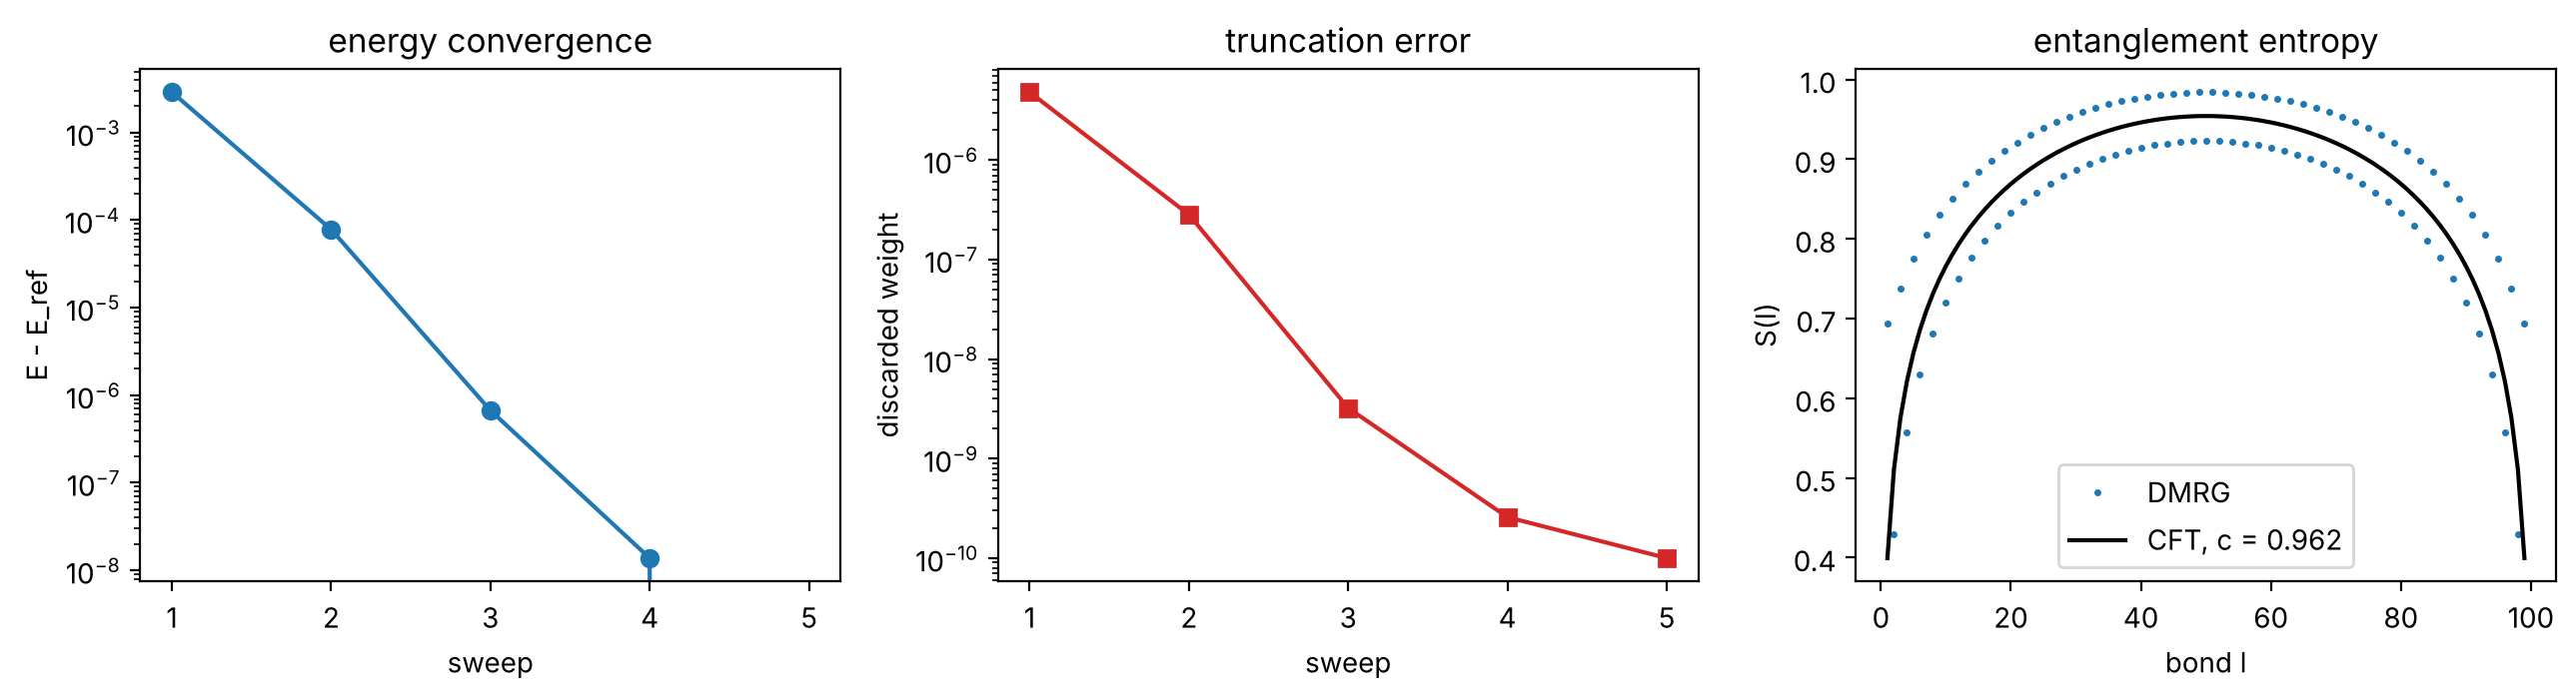

In [3]:
r = D.dmrg(D.heisenberg(100), chi=[16, 32, 64, 96, 128], sweeps=5, verbose=True)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].semilogy(range(1, len(r.energies) + 1), np.array(r.energies) + 44.12773986, "o-")
ax[0].set_xlabel("sweep"); ax[0].set_ylabel("E - E_ref"); ax[0].set_title("energy convergence")
ax[1].semilogy(range(1, len(r.truncation) + 1), r.truncation, "s-", c="tab:red")
ax[1].set_xlabel("sweep"); ax[1].set_ylabel("discarded weight"); ax[1].set_title("truncation error")
S = r.entropy; l = np.arange(1, 100)
c = D.calabrese_cardy_obc(S, 100)
ax[2].plot(l, S, ".", ms=3, label="DMRG")
x = np.log(200 / np.pi * np.sin(np.pi * l / 100))
ax[2].plot(l, c / 6 * x + np.mean(S[30:70] - c / 6 * x[30:70]), "k-", label=f"CFT, c = {c:.3f}")
ax[2].set_xlabel("bond l"); ax[2].set_ylabel("S(l)"); ax[2].legend(); ax[2].set_title("entanglement entropy")
plt.tight_layout()

Text(0.5, 1.0, 'critical antiferromagnetic correlations')

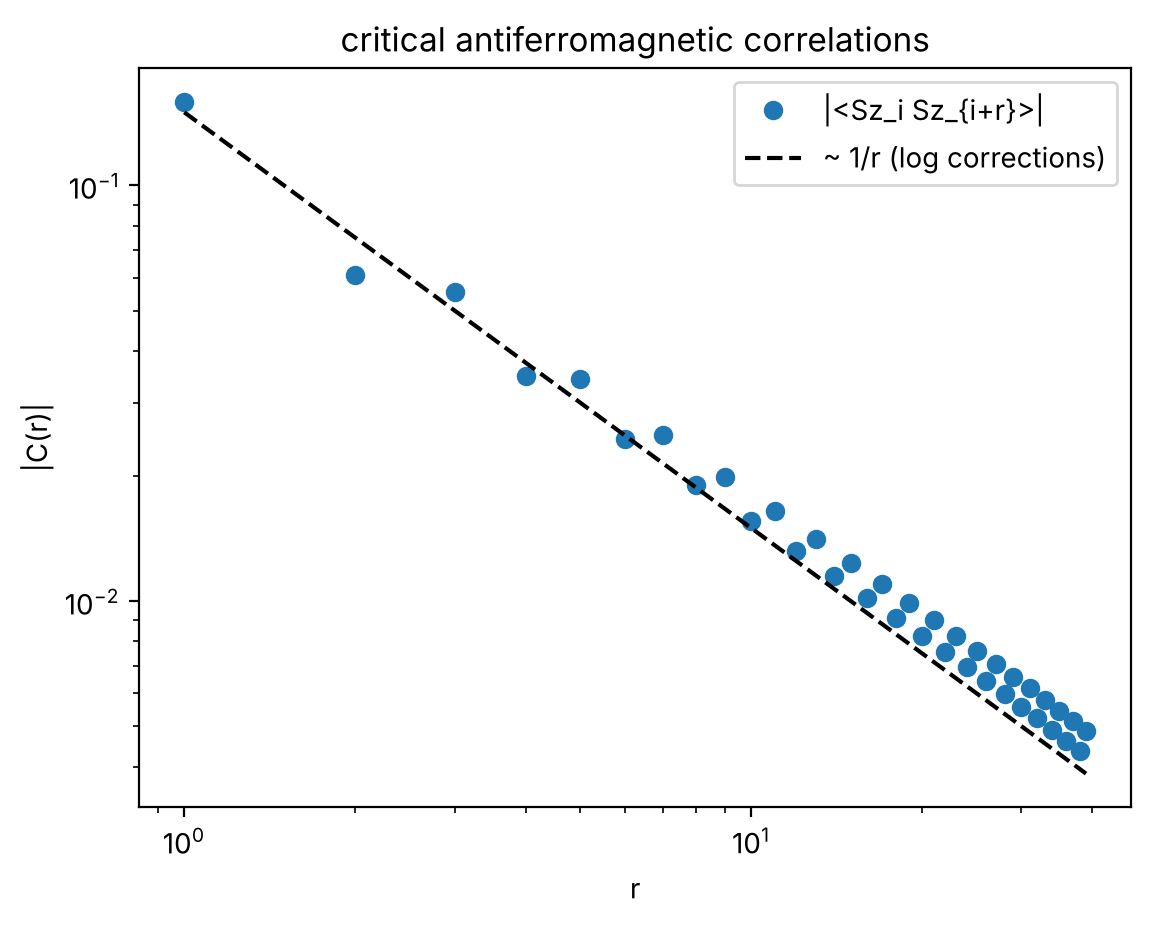

In [4]:
psi = r.mps
Sz = D.SPIN["Sz"]
i0 = 30
d = np.arange(1, 40)
C = np.array([psi.correlation(Sz, Sz, i0, i0 + x).real for x in d])
plt.loglog(d, np.abs(C), "o", label="|<Sz_i Sz_{i+r}>|")
plt.loglog(d, 0.15 / d, "k--", label="~ 1/r (log corrections)")
plt.xlabel("r"); plt.ylabel("|C(r)|"); plt.legend(); plt.title("critical antiferromagnetic correlations")

## 3 · The quantum Ising transition with DMRG
At the critical point $h=J$ the half-chain entanglement of an open chain grows as $S(L/2)=\frac{c}{6}\ln L+\text{const}$, and the slope gives the central charge $c=1/2$. DMRG energies agree with the exact free-fermion solution at every field. (In the ordered phase a finite chain's ground state is a cat state, nearly degenerate with the symmetry-broken states, so check entanglement there with care.)

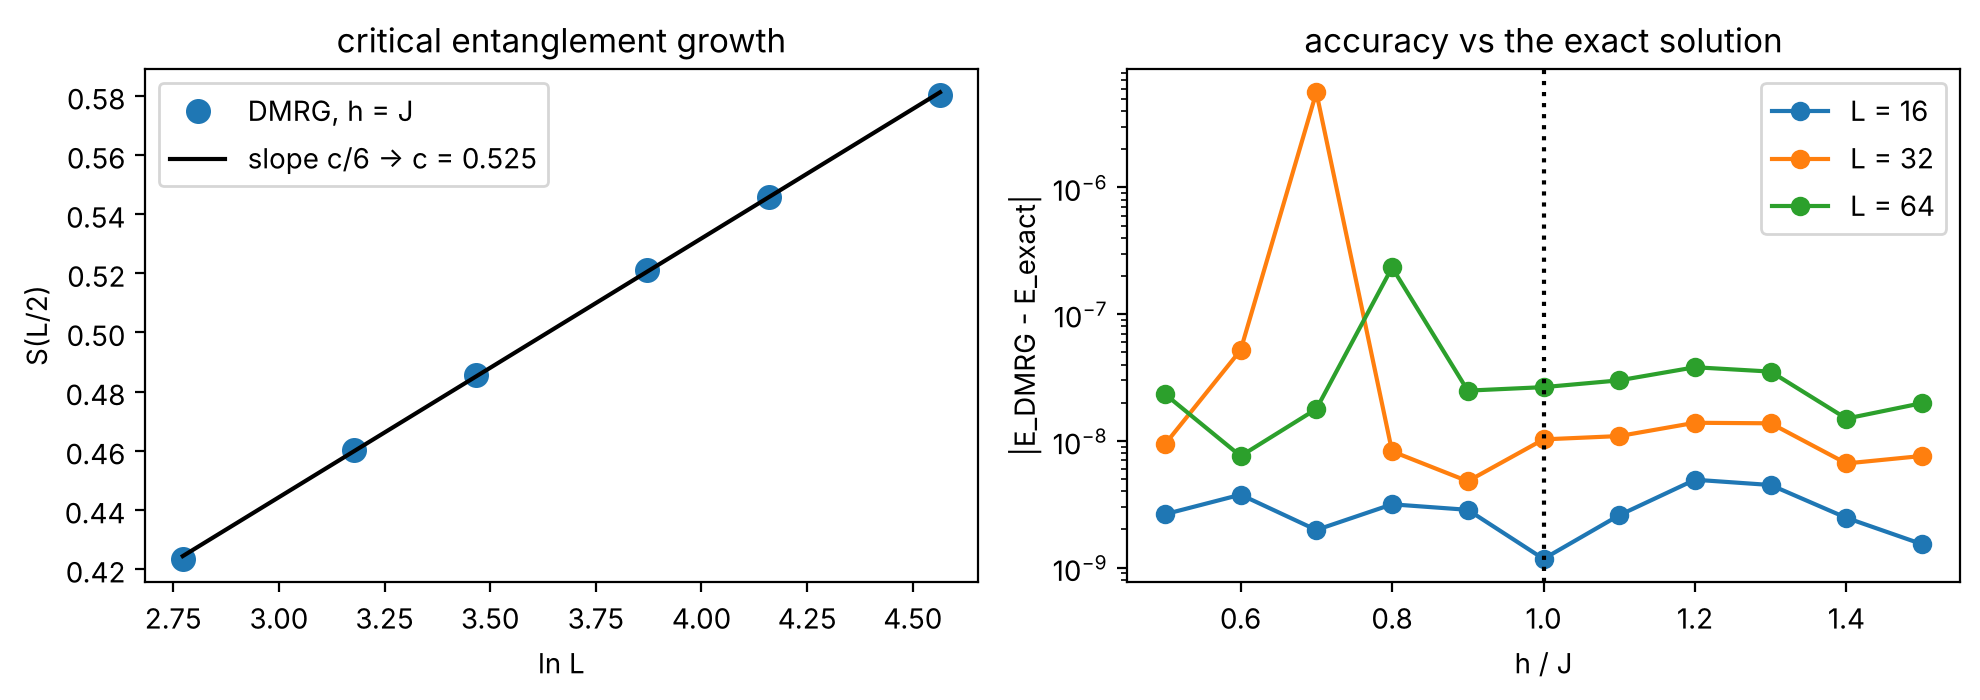

In [5]:
Ls = np.array([16, 24, 32, 48, 64, 96])
Sc = np.array([D.dmrg(D.tfim(L, 1.0, 1.0), chi=[16, 32, 48], sweeps=3).entropy[L // 2 - 1] for L in Ls])
slope, icpt = np.polyfit(np.log(Ls), Sc, 1)
hs = np.linspace(0.5, 1.5, 11)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(np.log(Ls), Sc, "o", ms=8, label="DMRG, h = J")
ax[0].plot(np.log(Ls), slope * np.log(Ls) + icpt, "k-", label=f"slope c/6 → c = {6 * slope:.3f}")
ax[0].set_xlabel("ln L"); ax[0].set_ylabel("S(L/2)"); ax[0].legend(); ax[0].set_title("critical entanglement growth")
for L in (16, 32, 64):
    err = [abs(D.dmrg(D.tfim(L, 1.0, h), chi=[16, 32, 48], sweeps=4).energy - D.tfim_exact_obc(L, 1.0, h)) for h in hs]
    ax[1].semilogy(hs, np.maximum(err, 1e-15), "o-", label=f"L = {L}")
ax[1].axvline(1, c="k", ls=":"); ax[1].set_xlabel("h / J"); ax[1].set_ylabel("|E_DMRG - E_exact|"); ax[1].legend()
ax[1].set_title("accuracy vs the exact solution")
plt.tight_layout()

## 4 · Haldane phase: AKLT and the spin-1 Heisenberg chain
The AKLT state is an exact MPS with $\chi=2$: energy $-2/3$ per bond and string order $-4/9$. The spin-1 Heisenberg chain is in the same (Haldane) phase, with string order ≈ −0.374.

AKLT: E0 = -26.0000000000  (exact -26.0000000000),  max chi = 2


Text(0.5, 1.0, 'hidden topological (string) order')

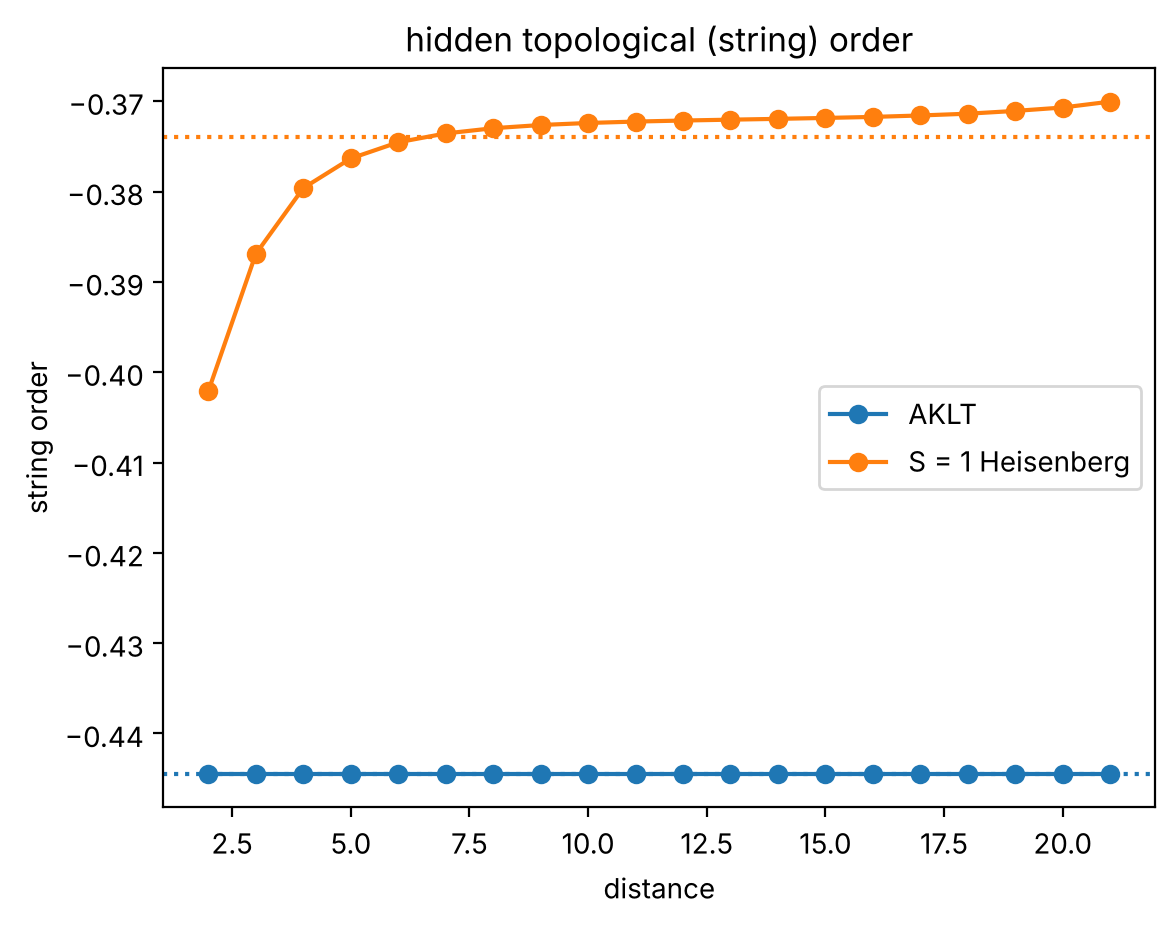

In [6]:
S1 = D.SPIN1
L = 40
ra = D.dmrg(D.aklt(L), chi=[8, 16], sweeps=3)
rh = D.dmrg(D.heisenberg(L, spin=1), chi=[16, 32, 48], sweeps=3)
print(f"AKLT: E0 = {ra.energy:.10f}  (exact {-2 / 3 * (L - 1):.10f}),  max chi = {max(ra.mps.bond_dims)}")
r_ = np.arange(2, 22)
for res, lab in ((ra, "AKLT"), (rh, "S = 1 Heisenberg")):
    so = [res.mps.correlation(S1["Sz"], S1["Sz"], 9, 9 + x, string=S1["string"]).real for x in r_]
    plt.plot(r_, so, "o-", label=lab)
plt.axhline(-4 / 9, c="tab:blue", ls=":"); plt.axhline(-0.374, c="tab:orange", ls=":")
plt.xlabel("distance"); plt.ylabel("string order"); plt.legend(); plt.title("hidden topological (string) order")

## 5 · Hubbard chain: Mott plateau and doping
The DMRG here does not fix the particle number, so scanning $\mu$ fills the chain. The density stays pinned at one electron per site over a window of width ≈ the charge gap: that plateau is the Mott insulator.

Text(0.5, 1.0, 'Hubbard chain L = 12, U = 4.0: Mott plateau')

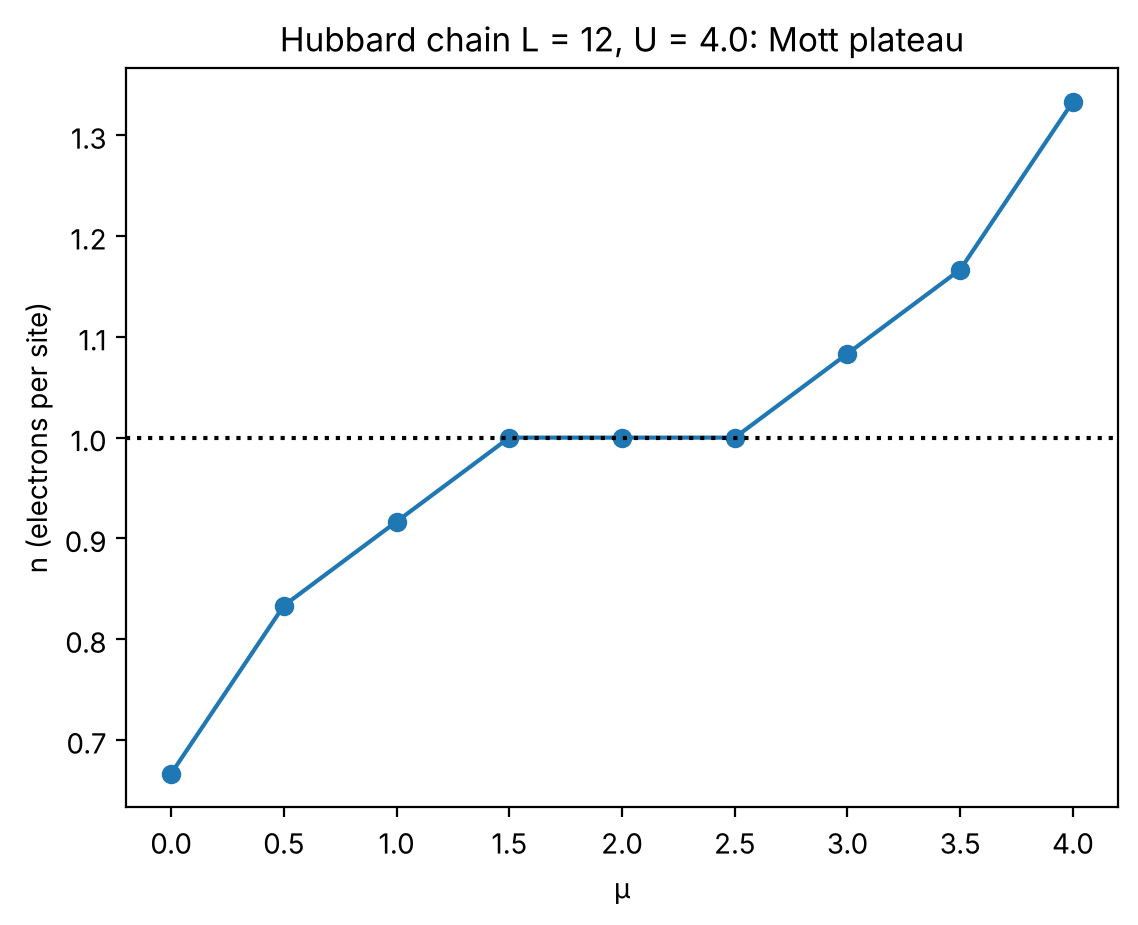

In [7]:
L, U = 12, 4.0
nu = D.ELECTRON["n"]
mus = np.linspace(0.0, 4.0, 9)
dens = []
for m_ in mus:
    rr = D.dmrg(D.hubbard(L, 1.0, U, mu=m_), chi=[24, 48], sweeps=3)
    dens.append(rr.mps.expect(nu).sum() / L)
plt.plot(mus, dens, "o-"); plt.axhline(1, c="k", ls=":")
plt.xlabel("μ"); plt.ylabel("n (electrons per site)"); plt.title(f"Hubbard chain L = {L}, U = {U}: Mott plateau")

DMRGResult(E0 = -25.5008819897, sweeps = 3, max chi = 48, trunc = 6.4e-09)


Text(0.5, 1.0, 'SSH-Hubbard: entanglement follows the dimerisation')

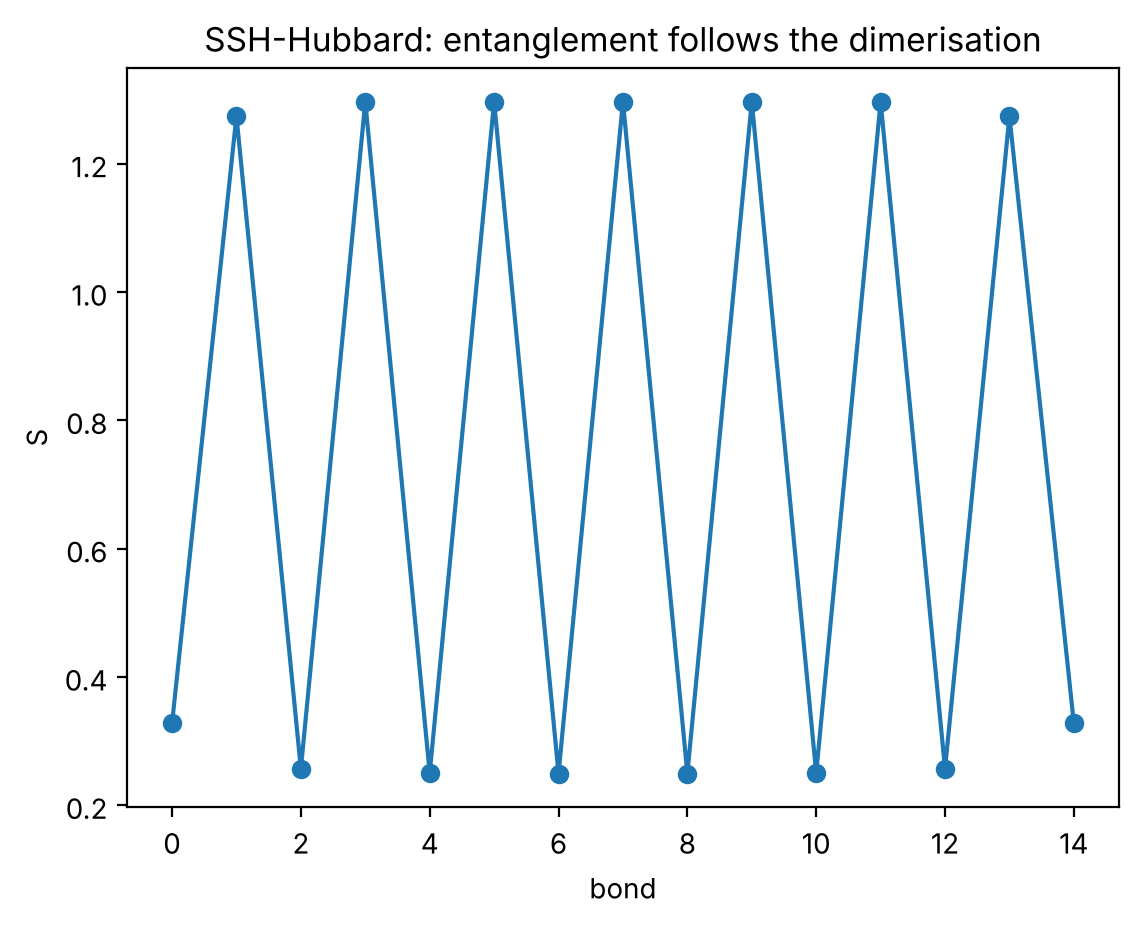

In [8]:
# any 1D hopforge model + interactions: SSH chain with Hubbard U
ssh = hf.models.ssh(v=0.5, w=1.0).make_spinful()
H = D.from_model(ssh, 8, U=2.0, mu=1.0)
rr = D.dmrg(H, chi=[24, 48], sweeps=3)
print(rr)
plt.plot(rr.entropy, "o-"); plt.xlabel("bond"); plt.ylabel("S"); plt.title("SSH-Hubbard: entanglement follows the dimerisation")

## Summary
* MPOs for any operator string; fermions handled by Jordan-Wigner strings.
* DMRG reaches converged energies of 100+ site chains in seconds to minutes, with the truncation error as an error bar.
* Entanglement gives central charges; string order identifies the Haldane phase; a μ scan finds the Mott gap.
* Benchmarks: $E_0(L=100)=-44.127739$, exact Ising energies, $c=1/2$ and $1$, AKLT $-2/3$ and $-4/9$, ED agreement for Hubbard.

---
## Quiz 22: DMRG and tensor networks

Twenty multiple-choice questions on this module. Run the next cell for a clickable
version (needs `ipywidgets`), or use the text version below it and grade yourself with
`quiz.check({1: 'a', 2: 'c', ...})`.

In [9]:
quiz = hf.Quiz(22)
quiz.interactive()

In [10]:
quiz.show()

=== Quiz 22: DMRG and matrix-product states ===

Q1. DMRG represents the ground state as
   (a) a plane-wave expansion
   (b) a matrix-product state with bond dimension chi
   (c) a Jastrow wavefunction
   (d) a Slater determinant

Q2. For a fixed bond dimension, the DMRG cost grows with system length L as
   (a) linearly
   (b) as L^6
   (c) exponentially
   (d) it is independent of L

Q3. The bond dimension needed is controlled by
   (a) the number of k-points
   (b) the temperature
   (c) the lattice constant
   (d) the entanglement entropy across each bond

Q4. Gapped 1D ground states obey
   (a) S ~ L
   (b) S = 0 always
   (c) a volume law
   (d) an area law: S saturates with block size

Q5. At a 1D quantum critical point with open boundaries, S(l) follows
   (a) (c/6) ln[(2L/pi) sin(pi l/L)] + const
   (b) exp(-l)
   (c) c l
   (d) a constant

Q6. The central charge of the critical Ising chain is
   (a) 2
   (b) 1
   (c) 0
   (d) 1/2

Q7. The central charge of the spin-1/2 Heise

In [11]:
my_answers = {
    1: '',
    2: '',
    3: '',
    4: '',
    5: '',
    6: '',
    7: '',
    8: '',
    9: '',
    10: '',
    11: '',
    12: '',
    13: '',
    14: '',
    15: '',
    16: '',
    17: '',
    18: '',
    19: '',
    20: '',
}
quiz.check(my_answers)

Q1: (no answer)
Q2: (no answer)
Q3: (no answer)
Q4: (no answer)
Q5: (no answer)
Q6: (no answer)
Q7: (no answer)
Q8: (no answer)
Q9: (no answer)
Q10: (no answer)
Q11: (no answer)
Q12: (no answer)
Q13: (no answer)
Q14: (no answer)
Q15: (no answer)
Q16: (no answer)
Q17: (no answer)
Q18: (no answer)
Q19: (no answer)
Q20: (no answer)

Score: 0 / 20


0